<a href="https://colab.research.google.com/github/MiikanGod/Classification/blob/main/Klasifikasi_Biner_(Student_Dropout).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# IMPORT LIBRARY & UPLOAD DATASET
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

In [6]:
from google.colab import files

print('Silakan upload file student_dropout_risk_2026.csv:')
uploaded = files.upload()

# Load Data
df = pd.read_csv('student_dropout_risk_2026.csv')
print(f'Ukuran Dataset: {df.shape[0]} baris, {df.shape[1]} kolom')

Silakan upload file student_dropout_risk_2026.csv:


Saving student_dropout_risk_2026.csv to student_dropout_risk_2026.csv
Ukuran Dataset: 100000 baris, 34 kolom


In [7]:
# PREPROCESSING DATA

# Menghapus kolom identifier yang tidak berpengaruh
df_clean = df.drop(columns=['person_id'])

# Encoding kolom kategorikal
cat_cols = df_clean.select_dtypes(include=['object']).columns
for col in cat_cols:
  le = LabelEncoder()
  df_clean[col] = le.fit_transform(df_clean[col])

# Memisahkan Fitur (X) dan Target (y)
X = df_clean.drop(columns=['dropout'])
y = df_clean['dropout']

# Split Data Training (80%) dan Testing (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [8]:
# TRAINING MODEL (RANDOM FOREST)

print('\nSedang melatih model Random Forest Classifier...')
model_rf = RandomForestClassifier(
    n_estimators=100, max_depth=12, random_state=42, n_jobs=-1
)
model_rf.fit(X_train, y_train)


Sedang melatih model Random Forest Classifier...


RandomForestClassifier(max_depth=12, n_jobs=-1, random_state=42)


 AKURASI MODEL: 83.08%

Classification Report:
              precision    recall  f1-score   support

    Stay (0)       0.85      0.92      0.88     13599
 Dropout (1)       0.78      0.65      0.71      6401

    accuracy                           0.83     20000
   macro avg       0.82      0.78      0.80     20000
weighted avg       0.83      0.83      0.83     20000



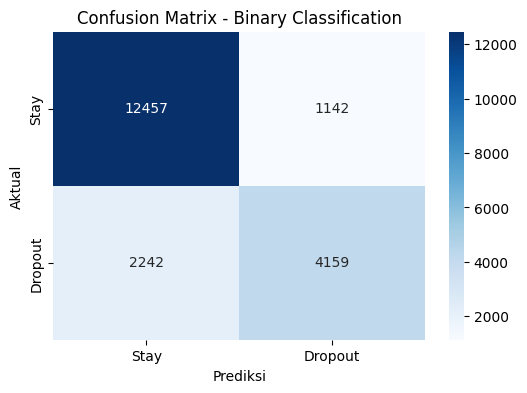

In [10]:
# EVALUASI MODEL
y_pred = model_rf.predict(X_test)

acc = accuracy_score(y_test, y_pred)
print(f'\n====================================')
print(f' AKURASI MODEL: {acc * 100:.2f}%')
print(f'====================================\n')

print('Classification Report:')
print(
    classification_report(y_test, y_pred, target_names=['Stay (0)', 'Dropout (1)'])
)

# Visualisasi Confusion Matrix
plt.figure(figsize=(6, 4))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Stay', 'Dropout'],
    yticklabels=['Stay', 'Dropout'],
)
plt.title('Confusion Matrix - Binary Classification')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.show()

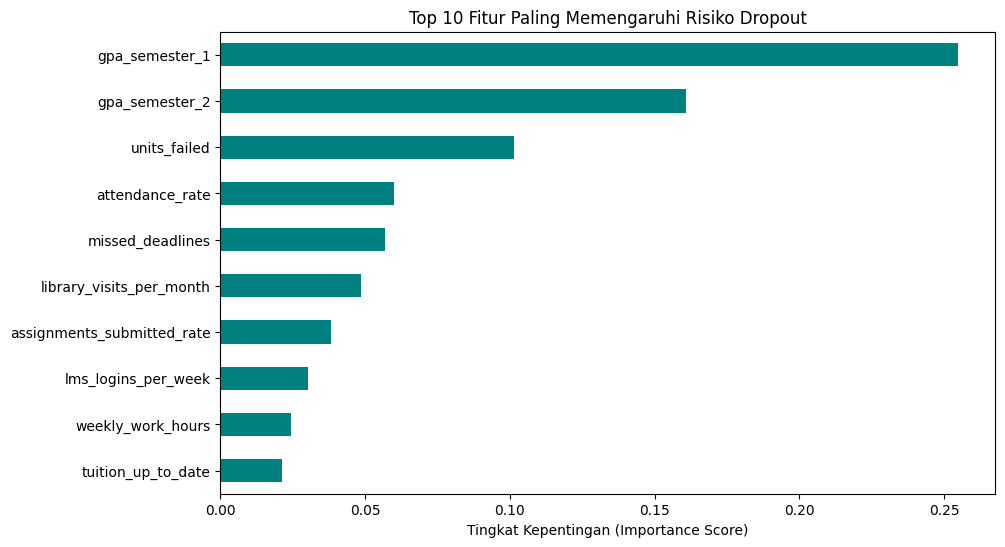

In [11]:
# FEATURE IMPORTANCES (Fitur Paling Berpengaruh)
importances = pd.Series(model_rf.feature_importances_, index=X.columns).sort_values(
    ascending=False
)

plt.figure(figsize=(10, 6))
importances.head(10).plot(kind='barh', color='teal')
plt.title('Top 10 Fitur Paling Memengaruhi Risiko Dropout')
plt.xlabel('Tingkat Kepentingan (Importance Score)')
plt.gca().invert_yaxis()
plt.show()